# Tutorial 01: First steps
This notebook will guide you through the first steps of using pyDAC.
First, you will learn how to:
- run an exemplary built-in steam-assisted-TVSA case
- extract and read what each step output
- show the step internal and outlet profiles
- compare the two ways a step can stop: after a fixed time or at an event.

### Overview
- **Case:** [`../cases/01_first_steps.json`](../cases/01_first_steps.json): 
  a built-in default on a coarse 1D grid (50 axial cells), \
  with the step profile plots switched on.
- **Runtime:** about a minute and a half for each of the two runs (seven steps each).
- **Memory and disk:** under 1 GB of memory; about 90 MB on disk for the two runs.
- **Same tutorial without a notebook:** the terminal commands at the end.

### Before you start
1. Make sure you have installed pyDAC in a Python environment following -> [Installation](../../docs/guide/01_installation.md).
2. Open this notebook and select that environment as the kernel
   ([Use pyDAC in Jupyter](../../docs/guide/01_installation.md#use-pydac-in-jupyter)).
3. Run the cells in order, from the top.



Let's import the necessary modules for this tutorial.

In [1]:
# Import necessary libraries
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

import pydac
print("pyDAC", pydac.__version__)

pyDAC 3.0.0


## How pyDAC works

Everything pyDAC needs to know about one simulation is in a **case**.

### What is a case?
A case is the complete set of inputs of one simulation, written as a JSON file:
- the column (size and wall) and the grid (1D or 2D, number of cells);
- the sorbent, with its isotherm and its uptake kinetics;
- the gas: which species it contains, and which of them adsorb;
- every step of the cycle: feed, temperatures, pressures, duration, when to stop;
- the run options: which plots to make, where to write the results.

You *RARELY* write all of it yourself.
pyDAC comes with a complete built-in case: you only state what you want to change.

There are two ways to do it:

**1. Preset**: a JSON file with just the fields that differ from the built-in defaults.
- Use it for *your* case: the one you keep, change and reuse.
- With the same pyDAC version, the same preset always gives the same case.
- Want to share a run so that anyone gets exactly your numbers? Save the *complete* case (`pydac.export_case`) and load it with `exact=True`: [tutorial 02](02_custom_case.ipynb) shows how.
- The file of this tutorial is a preset.

**2. Settings**: single fields changed *on top* of the preset, via Python or the terminal.
- From Python: `pydac.load_case(PRESET, settings={"grid.nz": 50})`
- From the terminal: `--set grid.nz=50`
- Use them for quick variations, without editing the file: try another value,
  compare two options, scan a parameter in a loop.
- A setting overrides the preset. When a change becomes permanent, move it into the preset.

Each source overrides the one before (the last one wins): **built-in defaults → preset → settings**.


Examples: later in this notebook, we will use a setting that changes how the steps stop.\
[Tutorial 02](02_custom_case.ipynb) builds a whole case setting by setting.\
[Tutorial 04](04_1d_vs_2d.ipynb) turns the same case from 2D into 1D with one setting (`grid.nr`).

pyDAC fills in the rest from the defaults and checks the whole case before running.
An inconsistent case is refused, with a message that says what is wrong.

### The workflow
1. **Load** the case: `pydac.load_case(...)` builds it and checks it.
2. **Run** it:
   - `pydac.run_steps` runs each step of the cycle once (this tutorial);
   - `pydac.run_css` repeats the cycle until it settles ([tutorial 03](03_css_tvsa.ipynb));
   - `pydac.run_nsga2` optimizes it ([tutorial 05](05_nsga2_trial.ipynb)).
3. **Read** the results: tables and plots for every step, in the run folder.

Each case gets its own run folder under `simulation_results/`.\
The folder is named after a *fingerprint* of the case:\
the same case always writes to the same folder, a changed case to a new one.

More in the guide: [Quick start](../../docs/guide/02_quickstart.md) and
[Cases and settings](../../docs/guide/03_cases.md).

### The case of this tutorial
- **Column**: the built-in one, 1 L of amine sorbent (length over diameter 0.5).
- **Feed**: humid air, 400 ppm CO2, relative humidity 0.5, 25 °C.
- [**`Preset`**](../cases/01_first_steps.json): it states only the grid (coarse 1D grid with 50 axial cells)\
   and the output options (step plots as PNG, a short progress report instead of the full solver log).\
   Every other field takes its built-in default.

In [2]:
# Show the preset case: only the fields that differ from the built-in defaults
CASE = Path("../cases/01_first_steps.json")
print(CASE.read_text())

# Build the complete case (built-in defaults + preset) and check it
case = pydac.load_case(CASE)

{
  "schema_version": 8,
  "simulation": {
    "grid": {
      "nz": 50,
      "nr": 1
    }
  },
  "execution": {
    "plot_profiles": true,
    "plot_format": "png",
    "print_to_terminal": false,
    "print_cycle_build": false,
    "extra_tag": "tutorial_01"
  }
}



### Curious about everything you can change?

The preset above shows only a few fields, but the case has many more.
- `export_case` saves the *complete* case (every field, with its value) as a JSON file.
- The file goes in `output_cases/`, next to this notebook: pyDAC creates the folder if it is missing.
- Open that file in your editor to browse it: it is the full list of what you can change.
- Below we print only the `execution` section, as a hint of what you will find.
- Every field you see can go in a preset, or be changed with a setting.

In [3]:
# Save the complete case: built-in defaults + preset, every field!
full_case = pydac.export_case(case, "output_cases/01_full_case.json", overwrite=True)
print("Complete case saved in", full_case)

# Print just one section of it: the run options (`execution`)
print(json.dumps(json.loads(full_case.read_text())["execution"], indent=2))

Complete case saved in output_cases/01_full_case.json
{
  "compute_numerical_sparsity": false,
  "css_probe_step": null,
  "css_tolerance": 0.005,
  "cvode_sparsity_mode": "pde_only",
  "cycle_options": {},
  "cycle_steps": null,
  "extra_tag": "tutorial_01",
  "generate_kpi_outputs": true,
  "keep_only_final_cycle": false,
  "max_cycles": 50,
  "output_root": "simulation_results",
  "plot_cyclic_profiles": true,
  "plot_final_cycle_profiles": false,
  "plot_format": "png",
  "plot_profiles": true,
  "print_cycle_build": false,
  "print_to_terminal": false,
  "require_css": true,
  "resume_from_cycle": null,
  "solve": true,
  "step_options": {},
  "termination_mode": null,
  "use_sparsity": true
}


## The *step* run

`run_steps` solves only the cycle steps you select, one after the other.\
Here we run the default set:
- `startup`: the fresh bed adsorbs until it is loaded;
- `blow`: blowdown to vacuum;
- `heat`: wall heating;
- `s_des`: steam-assisted desorption;
- `cool`: cooling;
- `press`: pressurization;
- `ads`: adsorption.

Each step starts from the state the previous one left.

About `overwrite=True`:
- Every case writes into its own run folder, named after the case fingerprint.
- If that folder already exists, `overwrite=True` replaces it, so you can run the cell again.
- Without it, a second run of the same case is refused.

In [4]:
# Run startup + every step of the cycle once, and print where the results are written
result = pydac.run_steps(case, overwrite=True)
print(result.folder)

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_01_packed_bed_50230611
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_01_packed_bed_50230611

------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/step_mode/tutorial_01_packed_bed_50230611

                                               Starting Adsorption Cycle                                                
[TVSA] Starting step 'Startup' with solve=True, termination=time.
[TVSA] Completed step 'Startup' with stop=final time @ 39000.00 s.
[TVSA] Starting step 'Blowdown' with solve=True, termination=event (Maximum internal pressure reached the target vacuum level).
[TVSA] Completed step 'Blowdown' with stop=event (Maximum internal pressure reached the target vacuum level = 200.25 mbar) @ 

## Analysing the results

Every step folder holds `kpis.csv`: a table with the columns `Step, Species, KPI, Value`.

You can manually inspect the `kpis.csv` files in each step folder to see the values.

Alternatively, you can use python code to automatically extract key values from the `kpis.csv` files:
- the **duration** of the step;
- the **CO2 change** and the **H2O change**: how much the column's inventory changed (positive: the column took it up);
- the **CO2 saturation**: the mean CO2 loading as a percentage of the reference loading.

The reference loading is the loading in equilibrium with the reference gas.
- By default the reference gas is ambient air: 400 ppm CO2, relative humidity 0.5.
- [Tutorial 02](02_custom_case.ipynb) changes it.

In [5]:
# The steps of the default cycle, in the order they are run
STEPS = ["startup", "blow", "heat", "s_des", "cool", "press", "ads"]

def step_table(result):
    """Read kpis.csv of every step and collect four values per step."""
    rows = {}
    for step in STEPS:
        # Each step folder has its own table: Step, Species, KPI, Value
        table = pd.read_csv(result.results_folder / step / "kpis.csv")
        value = table.set_index(["Species", "KPI"])["Value"]
        # Pick the duration, the CO2 and H2O change, and the CO2 saturation
        rows[step] = {
            "duration [min]": value["system", "Step duration [s]"] / 60,
            "CO2 change [g]": 1000 * value["CO2", "mass change [kg]"],
            "H2O change [g]": 1000 * value["H2O", "mass change [kg]"],
            "CO2 saturation [%]": value["CO2", "Saturation [%]"],
        }
    return pd.DataFrame(rows).T.round(2)

# Build the table for the run above and show it
default_steps = step_table(result)
default_steps

,duration [min],CO2 change [g],H2O change [g],CO2 saturation [%]
startup,650.00,28.06,25.62,96.15
blow,1.78,0.00,-0.01,96.15
heat,150.00,-4.09,-8.89,82.02
s_des,60.00,-23.46,-9.30,1.75
cool,44.55,0.00,0.00,1.75
press,0.43,0.00,0.01,1.75
ads,650.00,28.06,18.23,97.89


What the table tells us:
- **Startup** loads about 28 g of CO2.
- **Wall heating** releases a few grams, which are vented.
- **Steam step** releases most of the rest, about 23 g.
  - That stream goes through the condenser.
  - About 21 g leave it as the product.
  - The rest dissolves in the condensed steam ([tutorial 03](03_css_tvsa.ipynb) follows the whole balance).
- **Blowdown, cooling and pressurization** move almost no CO2.

## Visualize the step profiles

With `execution.plot_profiles` = True, each step writes its figures.
- You can find them in the `STEP/profiles/` folder of the run.
- Their format is set by `execution.plot_format` (`png` here, so the notebook can show them).

Here the notebook will load three of them just for display. Usually, you would explore all the profiles in the respective folders.

startup: outlet species composition (breakthrough)


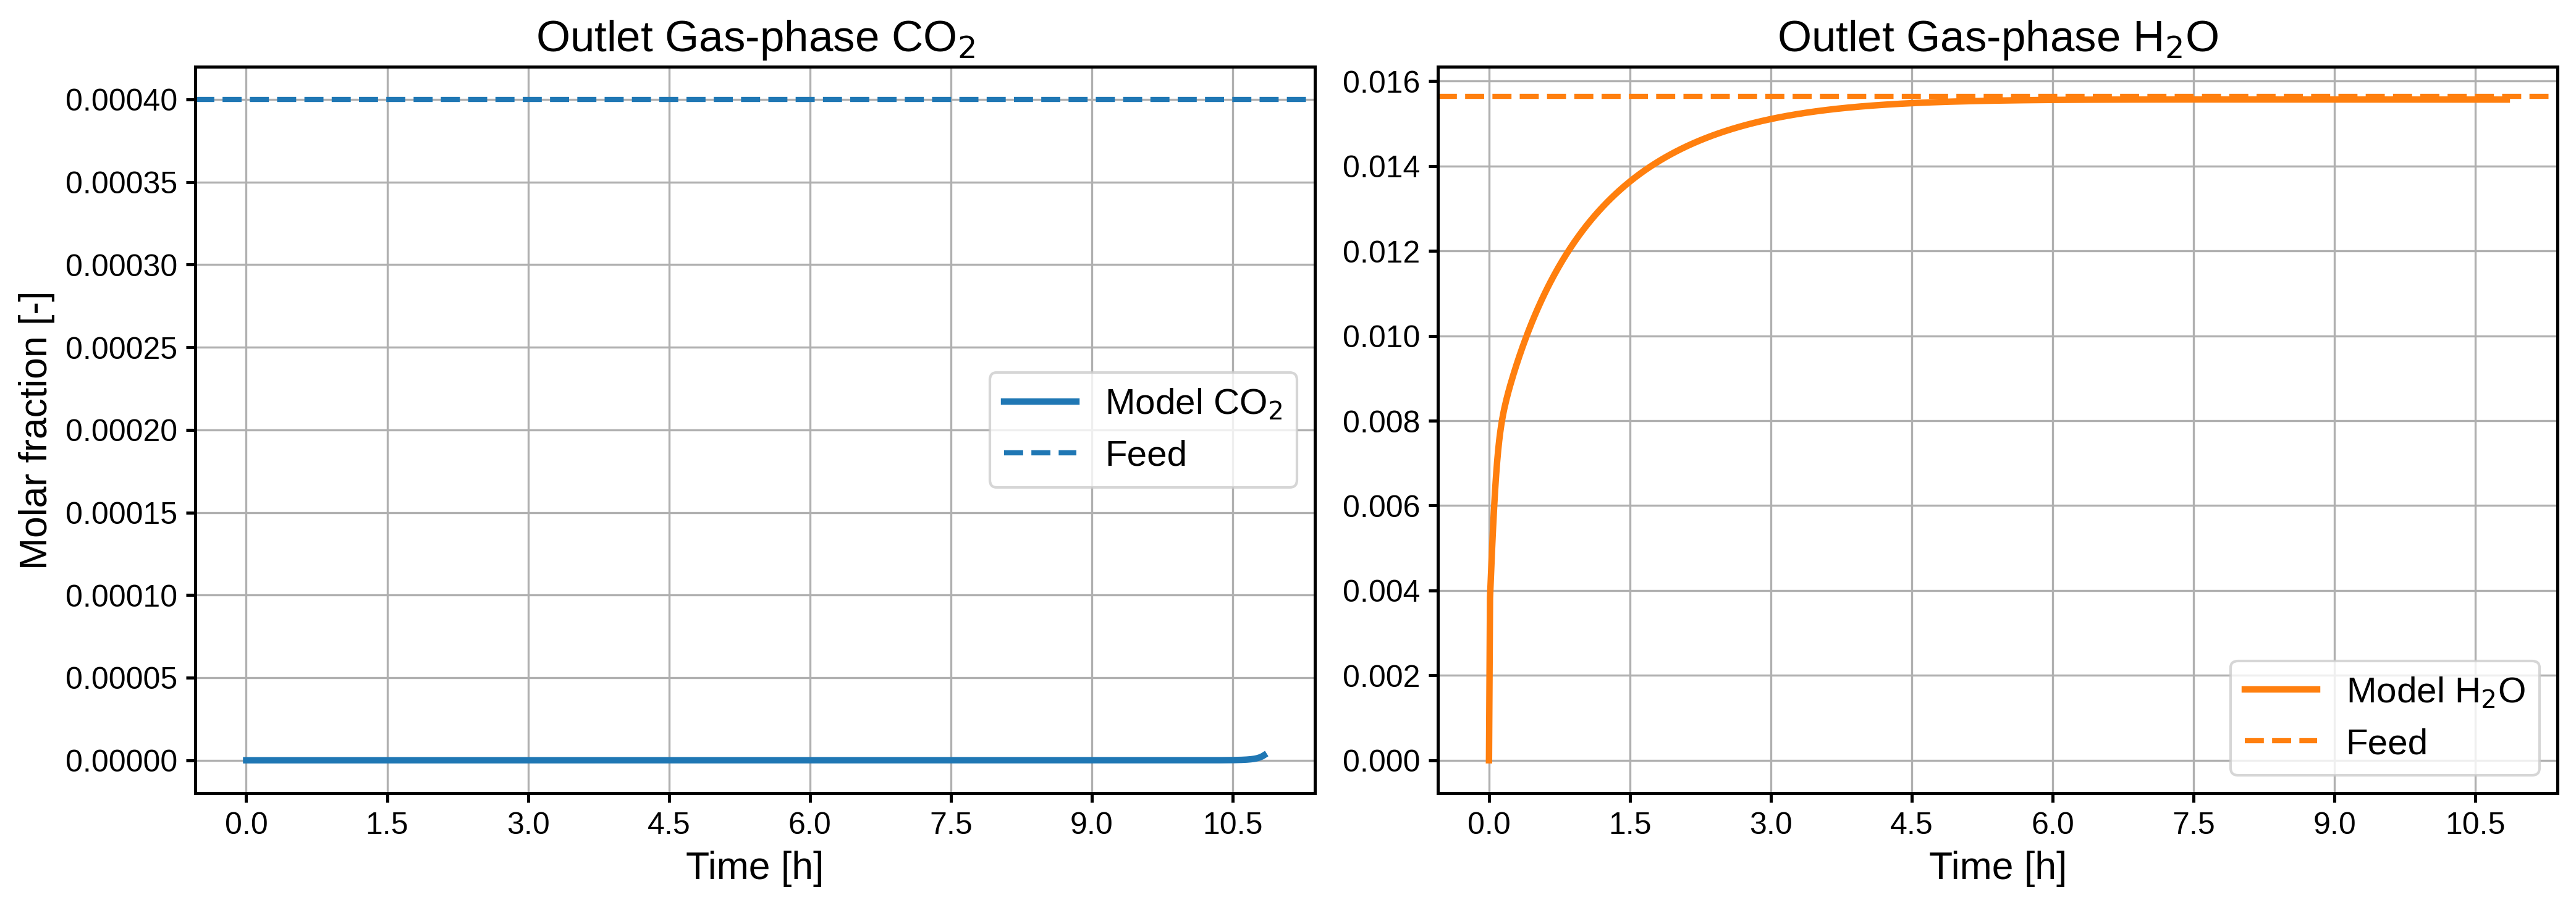

heat: bed and wall temperature along the column


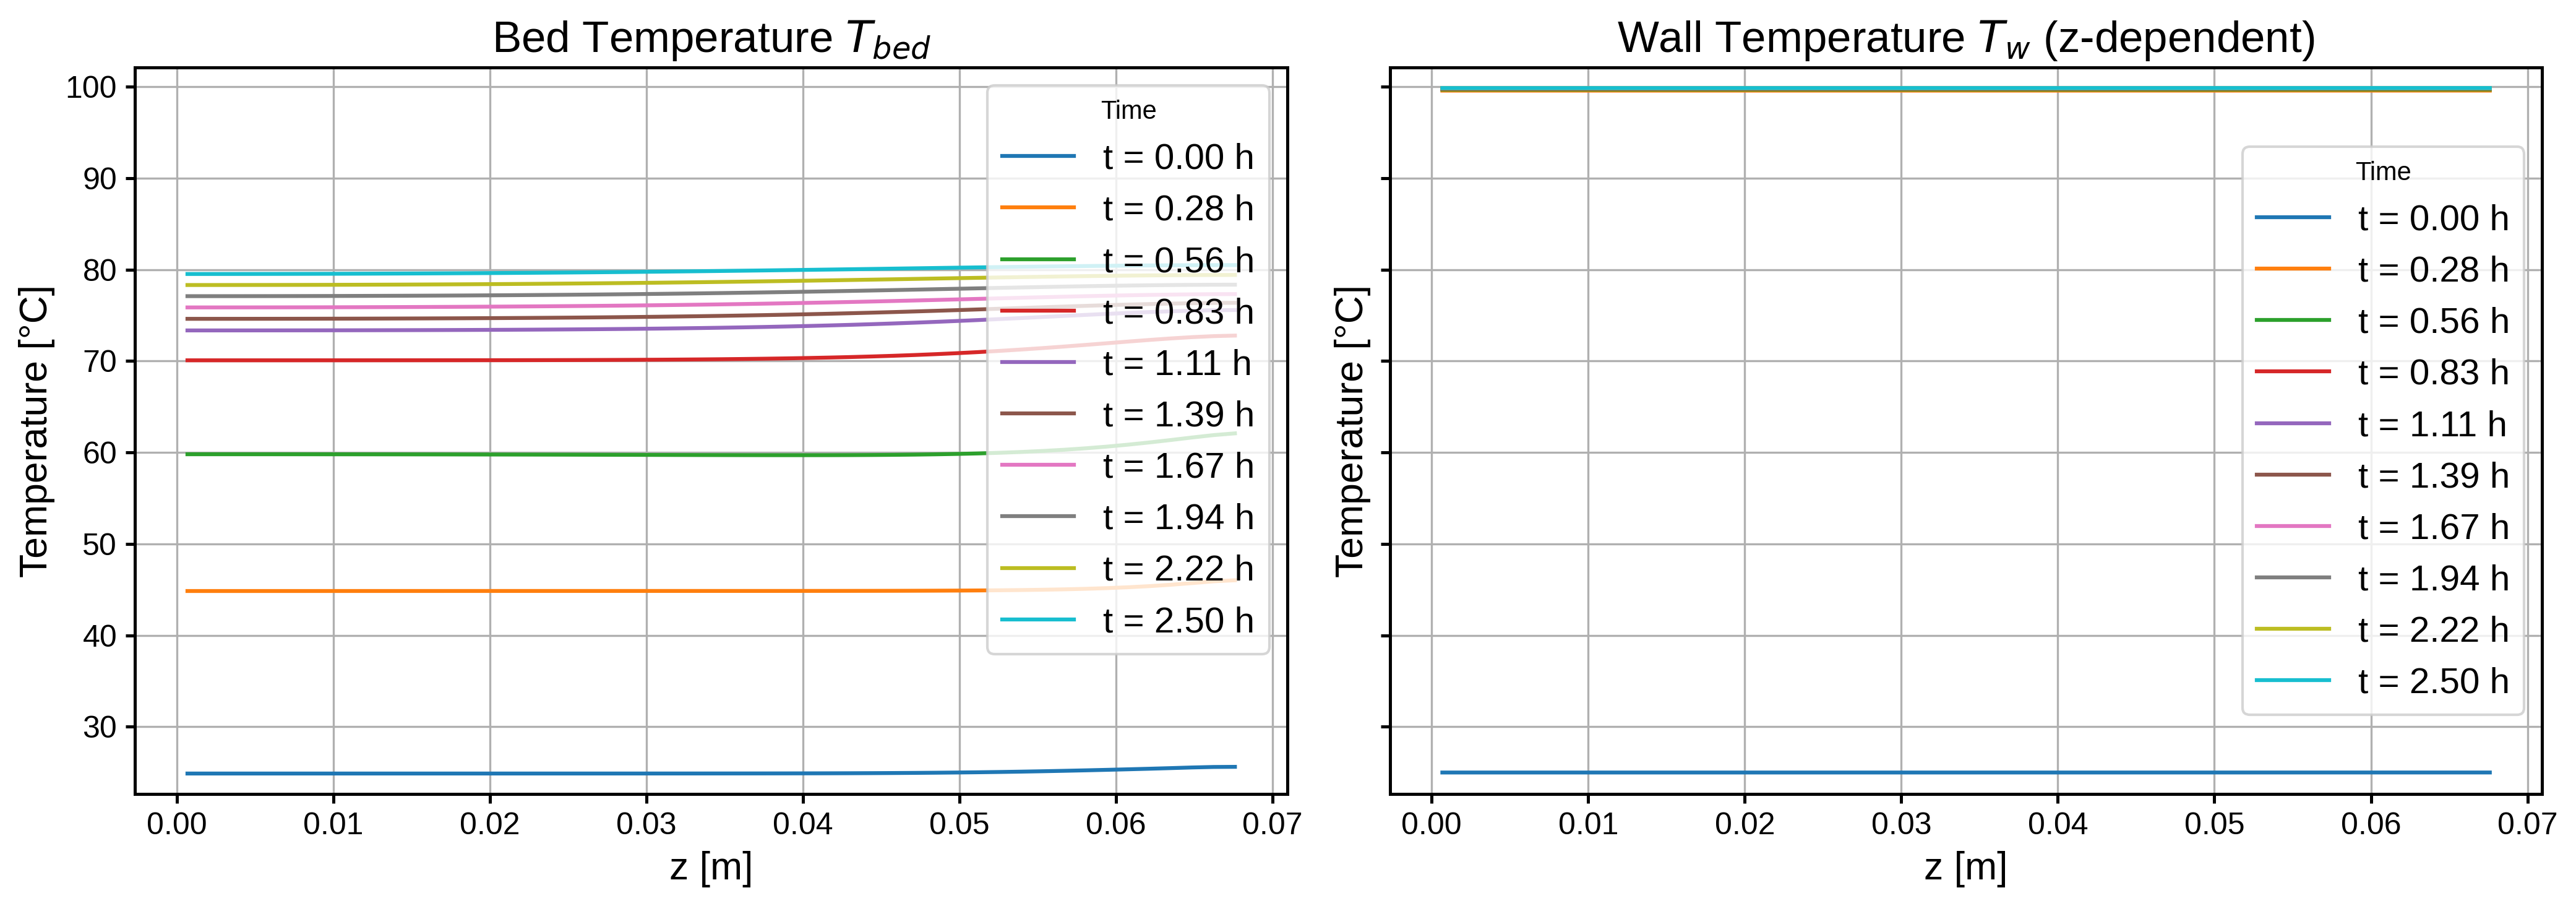

s_des: outlet composition


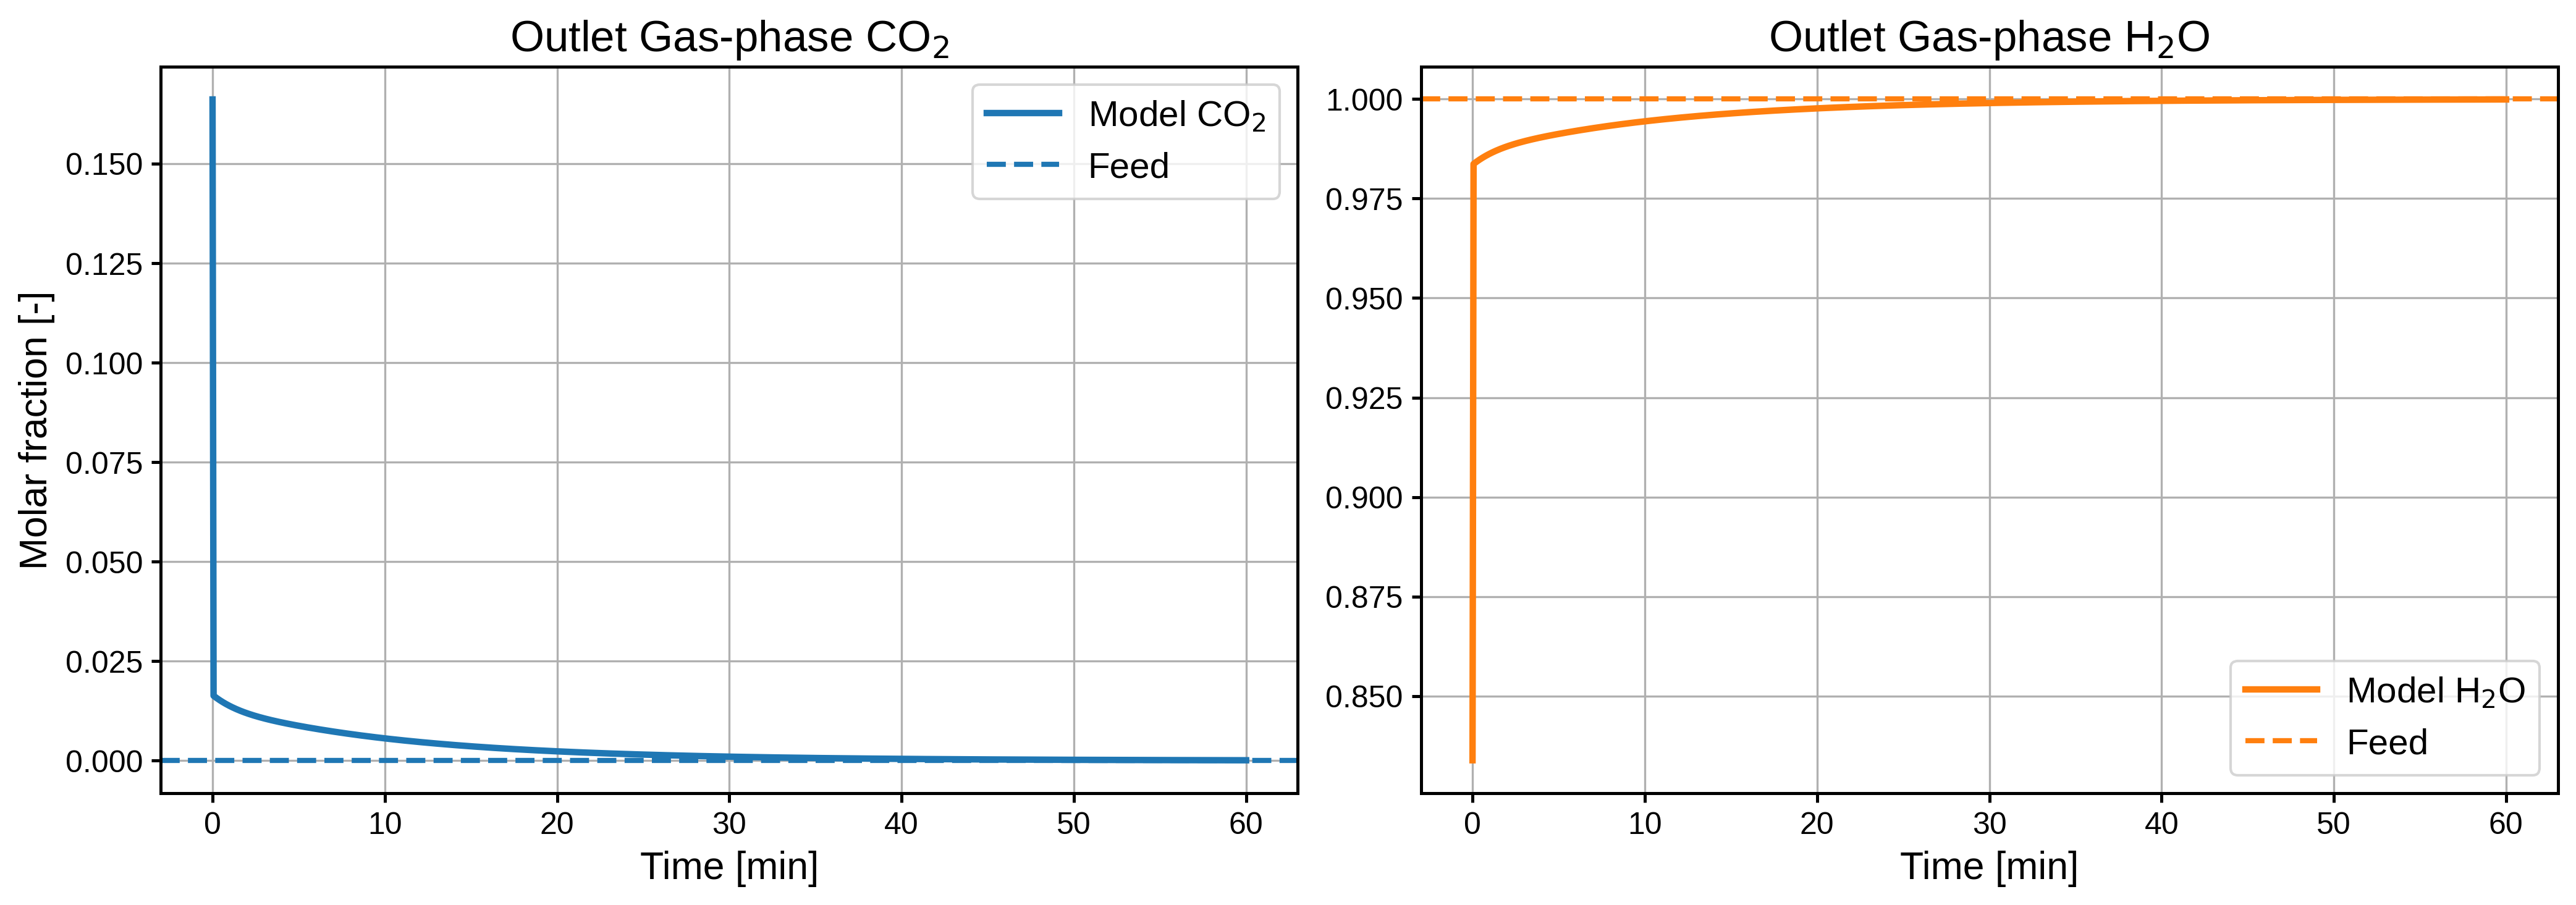

In [6]:
figures = {
    "startup: outlet species composition (breakthrough)": "startup/profiles/outlet_profiles/startup_outlet_species.png",
    "heat: bed and wall temperature along the column": "heat/profiles/internal_1D_profiles/heat_Tbed_Twall_axial_alltimes.png",
    "s_des: outlet composition": "s_des/profiles/outlet_profiles/s_des_outlet_species.png",
}
for title, path in figures.items():
    print(title)
    display(Image(filename=result.results_folder / path, width=700))

## Time or event? when a step stops

Each step stops in one of two ways:
- after a fixed time (`"time"`): its `horizon.nominal_time_s`;
- when a quantity crosses a threshold (`"event"`).

In the built-in case:
- `startup`, `ads`, `heat` and `s_des` run on **time**;
- `blow`, `cool` and `press` stop at an **event**.

The event of each step is fixed by its `termination` block. For example:
- `startup`, `ads`: the mean CO2 loading reaches 95 % of the reference loading;
- `heat`: the coldest point of the bed exceeds the steam condensation temperature;
- `s_des`: the mean CO2 loading drops below 5 %.


Let's try to change the termination mode with a *setting*, in code.

Using the setting `execution.termination_mode`, we will switch every step of the run to *one* mode.
- It changes the case, so the case gets a **new fingerprint**.
- A new fingerprint means a new run folder: the first run is not overwritten.
- Only the *same* case (same fingerprint) is overwritten by `overwrite=True`.

In [7]:
# Same preset, plus one setting: every step stops at its event
event_case = pydac.load_case(CASE, settings={"execution.termination_mode": "event"})

# Run it: it goes into its own run folder (new fingerprint)
event_result = pydac.run_steps(event_case, overwrite=True)
print(event_result.folder)

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_01_packed_bed_296b028c
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_01_packed_bed_296b028c



------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/step_mode/tutorial_01_packed_bed_296b028c

                                               Starting Adsorption Cycle                                                
[TVSA] Starting step 'Startup' with solve=True, termination=event (Average bed CO2 loading reached 95% of the reference capacity).
[TVSA] Completed step 'Startup' with stop=event (Average bed CO2 loading reached 95% of the reference capacity = 95.00%) @ 38534.53 s.
[TVSA] Starting step 'Blowdown' with solve=True, termination=event (Maximum internal pressure reached the target vacuum level).
[TVSA] Completed step 'Blowdown' with stop=event (Maximum internal pressure reached the target vacuum level = 200.25 mbar) @ 106.64 s.
[TVSA] Starting step 'Wall pre-heating' with solve=True, termination=event (Mi

In [8]:
# Same four values as before, now for the event run
event_steps = step_table(event_result)

# Put the two runs side by side
comparison = pd.DataFrame({
    "default: duration [min]": default_steps["duration [min]"],
    "event: duration [min]": event_steps["duration [min]"],
    "default: CO2 change [g]": default_steps["CO2 change [g]"],
    "event: CO2 change [g]": event_steps["CO2 change [g]"],
})
comparison

,default: duration [min],event: duration [min],default: CO2 change [g],event: CO2 change [g]
startup,650.00,642.24,28.06,27.73
blow,1.78,1.78,0.00,0.00
heat,150.00,33.94,-4.09,-0.00
s_des,60.00,42.75,-23.46,-26.27
cool,44.55,46.64,0.00,0.00
press,0.43,0.43,0.00,0.00
ads,650.00,608.66,28.06,26.27


What changes with events:
- **Heating** stops after about 34 minutes instead of 150.
  - It stops as soon as the whole bed is above the steam condensation temperature.
  - The bed is then too cold to release CO2, so almost none is vented.
- **Steam step** desorbs more, about 26 g instead of 23.
  - It stops after about 43 minutes, once the mean loading is below 5 %.
- **The cycle** is about three hours shorter.
- **The product** changes too:
  - The short heating flushes out less of the air left in the column after blowdown.
  - This single pass collects about 700 ppm of O2 with the CO2,\
    (against almost none on the default rules).
  - The product KPIs of a cycle are in [tutorial 03](03_css_tvsa.ipynb), the O2 limit of a campaign in [tutorial 05](05_nsga2_trial.ipynb).

Neither rule is right in general:
- fixed times keep cycles comparable;
- events adapt each step to the state of the bed.

The run prints the rule each step used and why it stopped.

To change only one step, set its own mode! For example `steps.heat.termination.mode = "event"`.
Please check the other modes and overrides listed in
[Running steps and cycles](../../docs/guide/04_running.md#when-a-step-stops).

## The same from the terminal

Run these from the folder of this notebook:

```bash
# The default run
pydac steps --config ../cases/01_first_steps.json --overwrite

# The event run: one extra setting
pydac steps --config ../cases/01_first_steps.json --set execution.termination_mode=event --overwrite
```

They write the same run folders as the cells above.

**Next:** [Tutorial 02: Build your own case](02_custom_case.ipynb).